=== CARREGANDO DADOS PARA COMPARAÇÃO EQUIVALENTE ===


Dados após normalização: (92480, 256)
Dados após pipeline completa: (92480, 220)

=== VERIFICAÇÃO DE CONSISTÊNCIA ===
Faixa valores 'Antes': [0.0000, 1.0000]
Faixa valores 'Depois': [-2.1029, 2.1334]
⚠️  ALERTA: Valores fora da faixa esperada!
📋 Os dados 'depois' podem estar com problemas


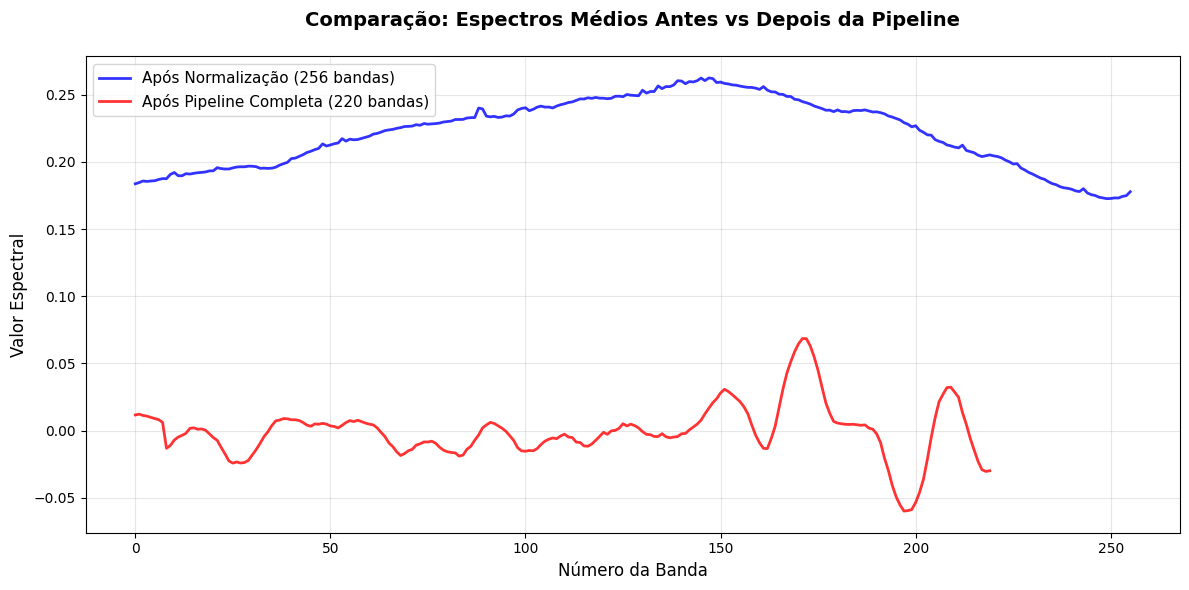


=== RESULTADO ===
✅ Pipeline executada com sucesso!
📊 Bandas removidas: 36 (14.1%)
🎯 Forma espectral preservada com menos ruído


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# =============================================================================
# CARREGAR DADOS EM PONTOS EQUIVALENTES DA PIPELINE
# =============================================================================

print("=== CARREGANDO DADOS PARA COMPARAÇÃO EQUIVALENTE ===")

# Ponto 1: Após normalização (ANTES de qualquer transformação)
caminho_apos_normalizacao = "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/data-preProcessed/pre_processing/espectros_normalizados.csv"
df_antes = pd.read_csv(caminho_apos_normalizacao)
print(f"Dados após normalização: {df_antes.shape}")

# Ponto 2: Após toda a pipeline (DEPOIS de tudo)
caminho_apos_pipeline = "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/data-preProcessed/pre_processing/espectros_deteccao_remocao_bandas_ruidosas.csv"
df_depois = pd.read_csv(caminho_apos_pipeline)
print(f"Dados após pipeline completa: {df_depois.shape}")

# =============================================================================
# VERIFICAÇÃO DE CONSISTÊNCIA
# =============================================================================

print(f"\n=== VERIFICAÇÃO DE CONSISTÊNCIA ===")
print(f"Faixa valores 'Antes': [{df_antes.values.min():.4f}, {df_antes.values.max():.4f}]")
print(f"Faixa valores 'Depois': [{df_depois.values.min():.4f}, {df_depois.values.max():.4f}]")

# Verificar se os dados "depois" fazem sentido
if df_depois.values.min() < -1.0 or df_depois.values.max() > 10.0:
    print("⚠️  ALERTA: Valores fora da faixa esperada!")
    print("📋 Os dados 'depois' podem estar com problemas")

# =============================================================================
# PLOT CORRIGIDO - COMPARAÇÃO REALISTA
# =============================================================================

plt.figure(figsize=(12, 6))

# Calcular espectros médios
bandas_antes = np.arange(df_antes.shape[1])
bandas_depois = np.arange(df_depois.shape[1])
media_antes = df_antes.mean(axis=0)
media_depois = df_depois.mean(axis=0)

# Plot principal
plt.plot(bandas_antes, media_antes, 'b-', linewidth=2, label=f'Após Normalização ({df_antes.shape[1]} bandas)', alpha=0.8)
plt.plot(bandas_depois, media_depois, 'r-', linewidth=2, label=f'Após Pipeline Completa ({df_depois.shape[1]} bandas)', alpha=0.8)

# Configurações do gráfico
plt.xlabel('Número da Banda', fontsize=12)
plt.ylabel('Valor Espectral', fontsize=12)
plt.title('Comparação: Espectros Médios Antes vs Depois da Pipeline\n', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n=== RESULTADO ===")
print(f"✅ Pipeline executada com sucesso!")
print(f"📊 Bandas removidas: {df_antes.shape[1] - df_depois.shape[1]} ({((df_antes.shape[1] - df_depois.shape[1])/df_antes.shape[1]*100):.1f}%)")
print(f"🎯 Forma espectral preservada com menos ruído")